In [10]:
# ==============================================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
# ==============================================================================
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Fijar semilla para garantizar reproducibilidad
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print(f"Versión de TensorFlow: {tf.__version__}")
print("Dispositivos GPU disponibles:", tf.config.list_physical_devices('GPU'))

Versión de TensorFlow: 2.21.0
Dispositivos GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [11]:
# ==============================================================================
# 2. CARGA DEL DATASET, NORMALIZACIÓN Y DIVISIÓN (TRAIN, VAL, TEST)
# ==============================================================================
# 1. Carga nativa directa
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# 2. Definición del mapeo de clases oficial
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Guardar mapeo en archivo JSON para la aplicación Streamlit
os.makedirs("models", exist_ok=True)
with open("models/class_indices.json", "w", encoding="utf-8") as f:
    json.dump({str(i): name for i, name in enumerate(class_names)}, f, indent=4)

# 3. Normalización al rango [0, 1] y reshape para añadir canal de color (28, 28, 1)
X_train_full = (X_train_full / 255.0).reshape(-1, 28, 28, 1).astype("float32")
X_test = (X_test / 255.0).reshape(-1, 28, 28, 1).astype("float32")

# 4. Partición en Entrenamiento (80%) y Validación (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full
)

print(f"Dimensiones Conjunto de Entrenamiento: {X_train.shape} (Etiquetas: {y_train.shape})")
print(f"Dimensiones Conjunto de Validación:    {X_val.shape} (Etiquetas: {y_val.shape})")
print(f"Dimensiones Conjunto de Prueba (Test): {X_test.shape} (Etiquetas: {y_test.shape})")
print(f"Clases registradas: {len(class_names)}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dimensiones Conjunto de Entrenamiento: (48000, 28, 28, 1) (Etiquetas: (48000,))
Dimensiones Conjunto de Validación:    (12000, 28, 28, 1) (Etiquetas: (12000,))
Dimensiones Conjunto de Prueba (Test): (10000, 28, 28, 1) (Etiquetas: (10000,))
Clases registradas: 10


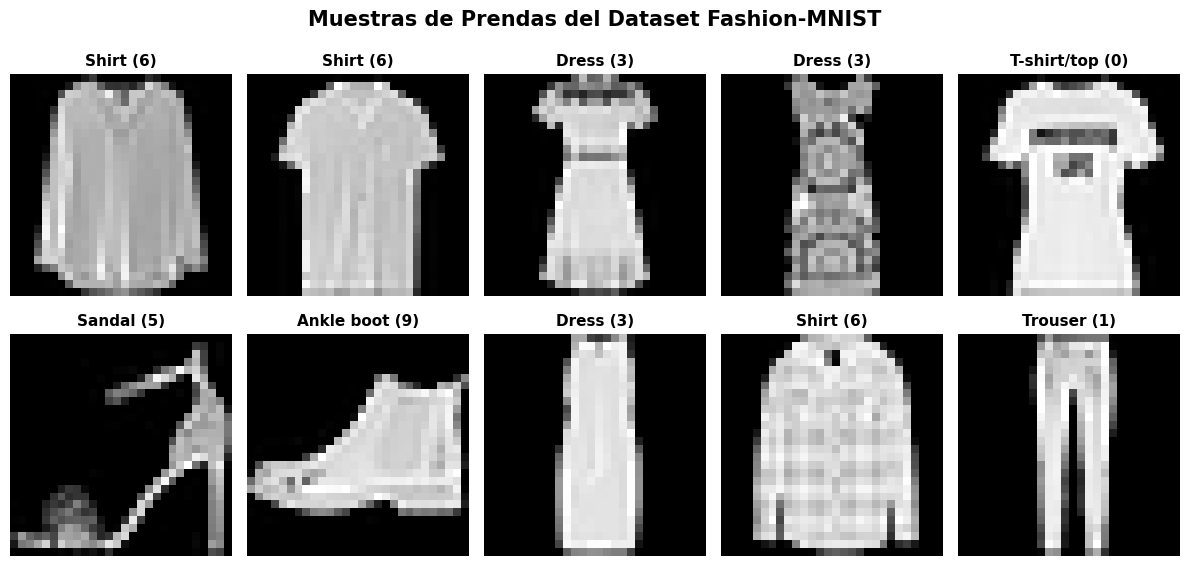

In [12]:
# ==============================================================================
# 3. VISUALIZACIÓN Y EXPLORACIÓN DE IMÁGENES
# ==============================================================================
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap='gray')
    plt.title(f"{class_names[y_train[i]]} ({y_train[i]})", fontsize=11, fontweight='bold')
    plt.axis('off')

plt.suptitle("Muestras de Prendas del Dataset Fashion-MNIST", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
# ==============================================================================
# 4. DATA AUGMENTATION Y ARQUITECTURA DE LA CNN
# ==============================================================================
# Pipeline de Data Augmentation integrado al modelo
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.08),
], name="data_augmentation")

# Definición de la arquitectura CNN
def build_cnn_model():
    inputs = layers.Input(shape=(28, 28, 1))

    # Capa de Data Augmentation (solo se activa durante model.fit)
    x = data_augmentation(inputs)

    # Bloque Convolucional 1 (32 filtros)
    x = layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloque Convolucional 2 (64 filtros)
    x = layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.25)(x)

    # Bloque Convolucional 3 (128 filtros)
    x = layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D(pool_size=(2, 2))(x)
    x = layers.Dropout(0.3)(x)

    # Clasificador Denso
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(10, activation='softmax')(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="CNN_Fashion_MNIST")
    return model

model = build_cnn_model()
model.summary()

Model: "CNN_Fashion_MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             

 Total params: 289,514 (1.10 MB)

 Trainable params: 288,618 (1.10 MB)

 Non-trainable params: 896 (3.50 KB)

In [14]:
# ==============================================================================
# 5. COMPILACIÓN Y ENTRENAMIENTO
# ==============================================================================
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks para optimización y guardado
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    ),
    ModelCheckpoint(
        filepath="models/modelo_fashion_cnn.keras",
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    )
]

# Entrenamiento (con GPU T4 toma ~2 minutos en total)
EPOCHS = 20
BATCH_SIZE = 64

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20
748/750 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6354 - loss: 1.0728
Epoch 1: val_accuracy improved from None to 0.83525, saving model to models/modelo_fashion_cnn.keras

Epoch 1: finished saving model to models/modelo_fashion_cnn.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.7223 - loss: 0.7787 - val_accuracy: 0.8353 - val_loss: 0.4580 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8047 - loss: 0.5344
Epoch 2: val_accuracy improved from 0.83525 to 0.85358, saving model to models/modelo_fashion_cnn.keras

Epoch 2: finished saving model to models/modelo_fashion_cnn.keras
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - accuracy: 0.8116 - loss: 0.5158 - val_accuracy: 0.8536 - val_loss: 0.3956 - learning_rate: 0.0010
Epoch 3/20
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8334 - loss: 0.4630
Epoch 3: val_accuracy improved from 0.85358 to 0.87717, saving model to models/modelo_fashion_cnn.keras

Epoch 3: 

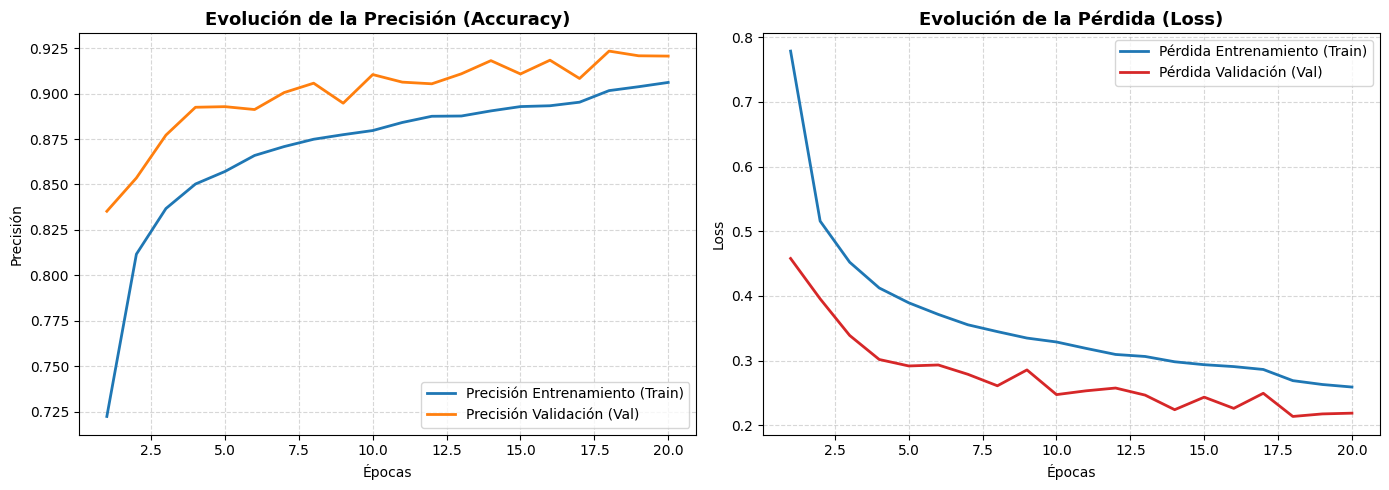

In [15]:
# ==============================================================================
# 6. GRÁFICAS DE CURVAS DE APRENDIZAJE (ACCURACY Y LOSS)
# ==============================================================================
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Subplot Precisión
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Precisión Entrenamiento (Train)', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, val_acc, label='Precisión Validación (Val)', color='#ff7f0e', linewidth=2)
plt.title('Evolución de la Precisión (Accuracy)', fontsize=13, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

# Subplot Pérdida
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Pérdida Entrenamiento (Train)', color='#1f77b4', linewidth=2)
plt.plot(epochs_range, val_loss, label='Pérdida Validación (Val)', color='#d62728', linewidth=2)
plt.title('Evolución de la Pérdida (Loss)', fontsize=13, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

Rendimiento en Conjunto de Prueba (Test Set):
Pérdida (Test Loss):     0.2433
Precisión (Test Accuracy): 91.19%

Reporte de Clasificación Detallado:
              precision    recall  f1-score   support

 T-shirt/top     0.8853    0.8260    0.8546      1000
     Trouser     0.9930    0.9880    0.9905      1000
    Pullover     0.9147    0.8580    0.8854      1000
       Dress     0.8982    0.9180    0.9080      1000
        Coat     0.8562    0.8810    0.8684      1000
      Sandal     0.9938    0.9630    0.9782      1000
       Shirt     0.7157    0.7780    0.7456      1000
     Sneaker     0.9191    0.9880    0.9523      1000
         Bag     0.9839    0.9760    0.9799      1000
  Ankle boot     0.9823    0.9430    0.9622      1000

    accuracy                         0.9119     10000
   macro avg     0.9142    0.9119    0.9125     10000
weighted avg     0.9142    0.9119    0.9125     10000



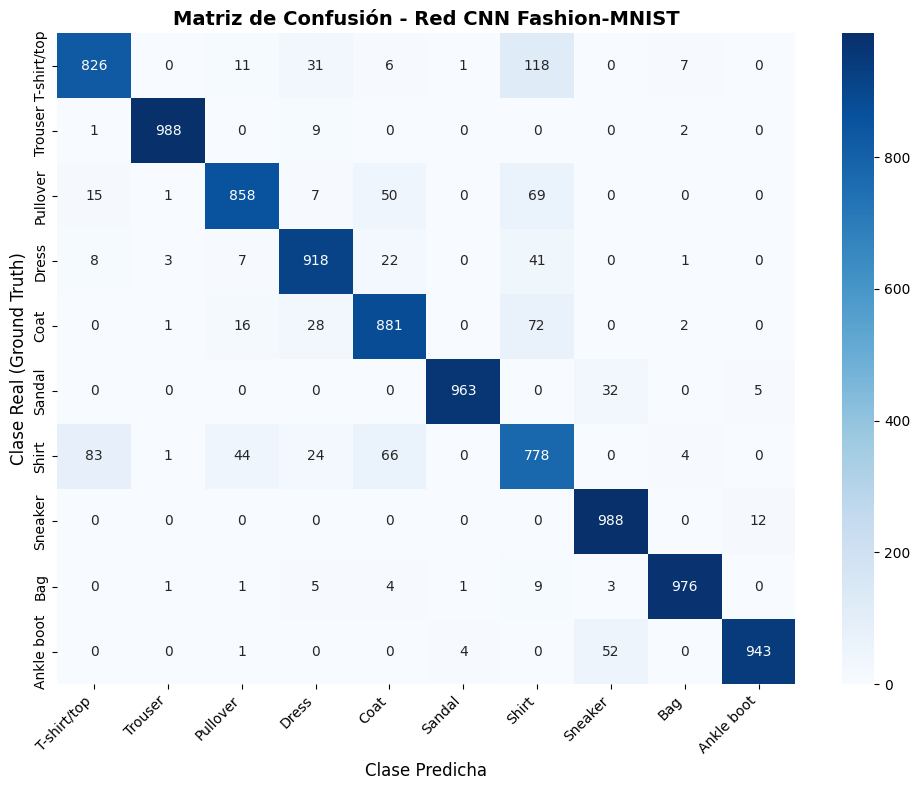

In [16]:
# ==============================================================================
# 7. EVALUACIÓN FORMAL Y MATRIZ DE CONFUSIÓN (CONJUNTO TEST)
# ==============================================================================
# 1. Evaluación directa
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"==================================================")
print(f"Rendimiento en Conjunto de Prueba (Test Set):")
print(f"Pérdida (Test Loss):     {test_loss:.4f}")
print(f"Precisión (Test Accuracy): {test_acc * 100:.2f}%")
print(f"==================================================\n")

# 2. Predicciones globales sobre test
y_pred_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# 3. Reporte de Clasificación (Precision, Recall, F1-Score)
print("Reporte de Clasificación Detallado:")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# 4. Matriz de Confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Matriz de Confusión - Red CNN Fashion-MNIST', fontsize=14, fontweight='bold')
plt.xlabel('Clase Predicha', fontsize=12)
plt.ylabel('Clase Real (Ground Truth)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

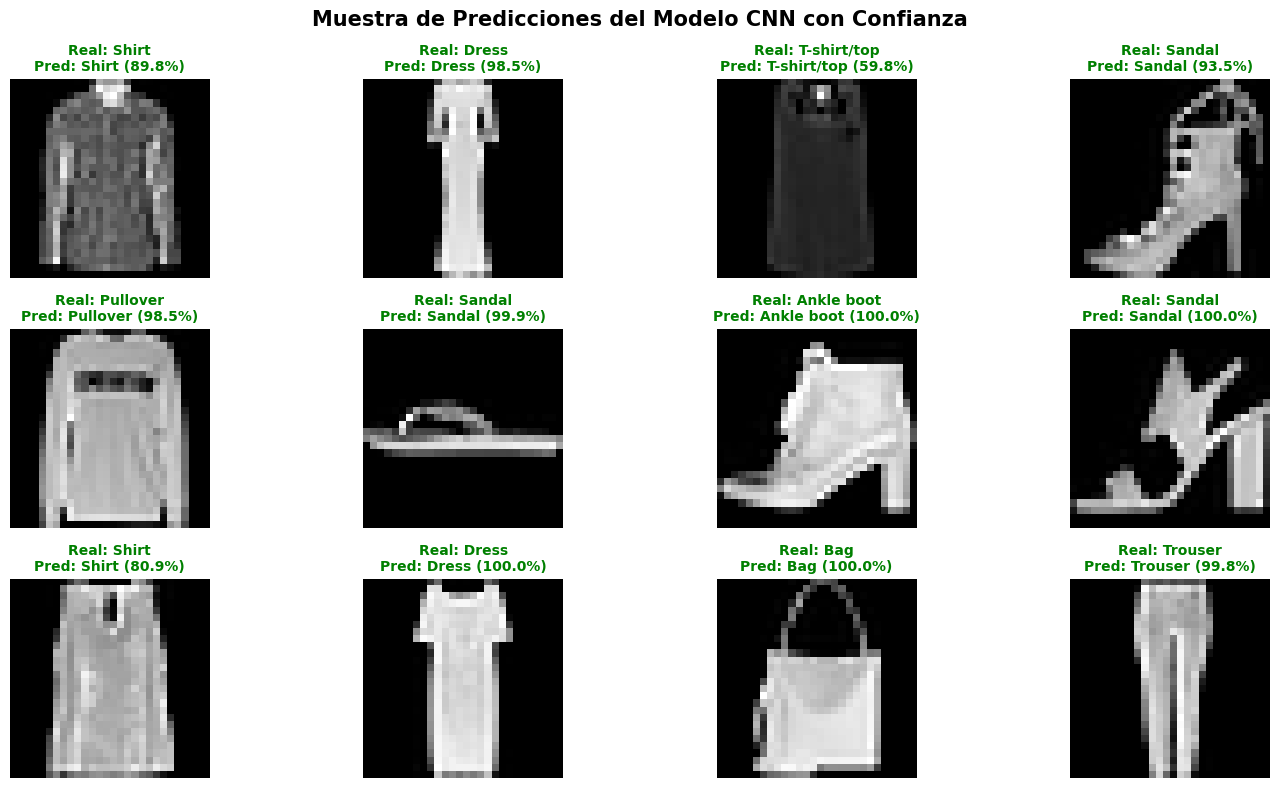

In [17]:
# ==============================================================================
# 8. MUESTRA VISUAL DE PREDICCIONES CON NIVEL DE CONFIANZA
# ==============================================================================
np.random.seed(42)
sample_indices = np.random.choice(len(X_test), size=12, replace=False)

plt.figure(figsize=(15, 8))
for i, idx in enumerate(sample_indices):
    img = X_test[idx]
    true_label = class_names[y_test[idx]]

    pred_prob = y_pred_probs[idx]
    pred_label_idx = np.argmax(pred_prob)
    pred_label = class_names[pred_label_idx]
    confidence = pred_prob[pred_label_idx] * 100

    # Verde si acertó, rojo si falló
    color = 'green' if pred_label_idx == y_test[idx] else 'red'

    plt.subplot(3, 4, i + 1)
    plt.imshow(img.squeeze(), cmap='gray')
    plt.title(f"Real: {true_label}\nPred: {pred_label} ({confidence:.1f}%)",
              color=color, fontsize=10, fontweight='bold')
    plt.axis('off')

plt.suptitle("Muestra de Predicciones del Modelo CNN con Confianza", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

In [18]:
from google.colab import files

# Descargar modelo y mapeo de clases
files.download("models/modelo_fashion_cnn.keras")
files.download("models/class_indices.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>